# Module 4: Operating Costs & Profitability Analytics
**Institution:** Invertis University, Bareilly (Faculty of Computer Applications)  
**Project:** ITC Hotels: Revenue & Business Performance Analysis (BCA Final Year Capstone)  
**Project Team:** Jatin Sagar (BC2023727), Atul Kumar (BC2023590), Darshika Rathore (BC2023687), Muskan Saxena (BC2023061)  
**Project Guide:** Ms. Megha Saxena, Assistant Professor  
**Database:** MySQL 8.0 / SQLite 3NF Database (`itc_hotel_analytics.db`)

---
## 1. Executive Summary & Business Context
Hospitality profitability requires adhering to the **USALI (Uniform System of Accounts for the Lodging Industry)** framework. Net yield depends on managing room operating expenses, F&B COGS, energy/utility expenses, and booking commissions.

This notebook models Gross Operating Profit (GOP), expense variance, and Net Profit Margin % across properties.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 6)

# Load via SQL from itc_hotel_analytics.db
db_path = '../ITC-Final-Dashboards/itc_hotel_analytics.db'
if os.path.exists(db_path):
    conn = sqlite3.connect(db_path)
    sql_query = """
    SELECT 
        oc.booking_id,
        r.hotel_name,
        r.arrival_date,
        r.arrival_year,
        r.arrival_month,
        r.is_canceled,
        oc.billed_nights,
        i.room_revenue_inr,
        (i.fnb_revenue_inr + i.banquet_revenue_inr) AS combined_fnb_banquet_rev_inr,
        i.minor_dept_revenue_inr,
        i.gross_total_revenue_inr AS gross_total_revenue_inr,
        oc.rooms_operating_cost AS rooms_operating_cost_inr,
        oc.fnb_cogs_cost AS fnb_cogs_operating_cost_inr,
        oc.distribution_commission AS booking_distribution_commission_inr,
        oc.energy_utility_cost AS energy_utility_cost_inr,
        oc.staff_payroll_cost AS staff_payroll_allocated_inr,
        oc.maintenance_cost AS property_maintenance_inr,
        oc.marketing_cost AS marketing_brand_cost_inr,
        oc.total_operating_expenses AS total_operating_expenses_inr,
        oc.gross_operating_profit AS gross_operating_profit_inr,
        oc.net_profit_margin_pct
    FROM operating_costs oc
    JOIN reservations r ON oc.booking_id = r.booking_id
    JOIN invoices i ON oc.booking_id = i.booking_id
    """
    df_cost = pd.read_sql_query(sql_query, conn)
    conn.close()
    print(f"✓ Successfully loaded {len(df_cost):,} records via SQL query")
else:
    df_cost = pd.read_csv('itc_operating_costs_profitability.csv')
    print(f"✓ Loaded {len(df_cost):,} records from CSV")

df_cost.head()

✓ Successfully loaded 87,396 records via SQL query


,booking_id,hotel_name,arrival_date,arrival_year,arrival_month,is_canceled,billed_nights,room_revenue_inr,combined_fnb_banquet_rev_inr,minor_dept_revenue_inr,...,rooms_operating_cost_inr,fnb_cogs_operating_cost_inr,booking_distribution_commission_inr,energy_utility_cost_inr,staff_payroll_allocated_inr,property_maintenance_inr,marketing_brand_cost_inr,total_operating_expenses_inr,gross_operating_profit_inr,net_profit_margin_pct
0,ITC-2015-000001,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,1,0.0,0.00,0.00,...,708.86,0.00,0.00,648.01,975.19,180.67,0.00,2512.73,-2512.73,0.00
1,ITC-2015-000002,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,1,0.0,552284.53,0.00,...,783.97,0.00,0.00,656.80,869.01,174.17,0.00,2483.95,549800.58,99.55
2,ITC-2015-000003,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,1,6375.0,340041.70,426.35,...,734.86,1022.78,824.70,764.82,974.23,201.75,166.66,4689.80,342153.25,98.65
3,ITC-2015-000004,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,1,6375.0,2932.34,564.55,...,778.23,909.03,516.82,652.28,1093.01,325.22,149.10,4423.69,5448.20,55.19
4,ITC-2015-000005,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,2,16660.0,597726.91,1496.38,...,1275.50,1206.30,2008.94,1356.08,2326.84,458.05,731.80,9363.51,606519.78,98.48


## 2. Financial Performance & GOP Executive Scorecard

In [2]:
valid_cost = df_cost[df_cost['is_canceled'] == 0]

gross_rev_cr = valid_cost['gross_total_revenue_inr'].sum() / 1e7
total_exp_cr = valid_cost['total_operating_expenses_inr'].sum() / 1e7
gop_cr = valid_cost['gross_operating_profit_inr'].sum() / 1e7
avg_gop_margin = (gop_cr / gross_rev_cr) * 100

print("="*60)
print(f"ITC HOTELS USALI PROFITABILITY SCORECARD")
print("="*60)
print(f"Gross Portfolio Revenue    : ₹ {gross_rev_cr:,.2f} Crores")
print(f"Total Operating Expenses   : ₹ {total_exp_cr:,.2f} Crores")
print(f"Gross Operating Profit (GOP): ₹ {gop_cr:,.2f} Crores")
print(f"GOP Margin                 : {avg_gop_margin:.2f}%")
print("="*60)

ITC HOTELS USALI PROFITABILITY SCORECARD
Gross Portfolio Revenue    : ₹ 1,565.15 Crores
Total Operating Expenses   : ₹ 97.27 Crores
Gross Operating Profit (GOP): ₹ 1,467.87 Crores
GOP Margin                 : 93.79%


## 3. USALI Operating Expense Breakdown

,Expense Category,Amount_Cr
2,OTA Commission,25.408369
4,Staff Payroll,21.636689
3,Energy & Utilities,14.958376
0,Rooms Operations,14.949578
1,F&B COGS,7.403173
6,Brand & Marketing,6.836883
5,Property Maintenance,6.080684


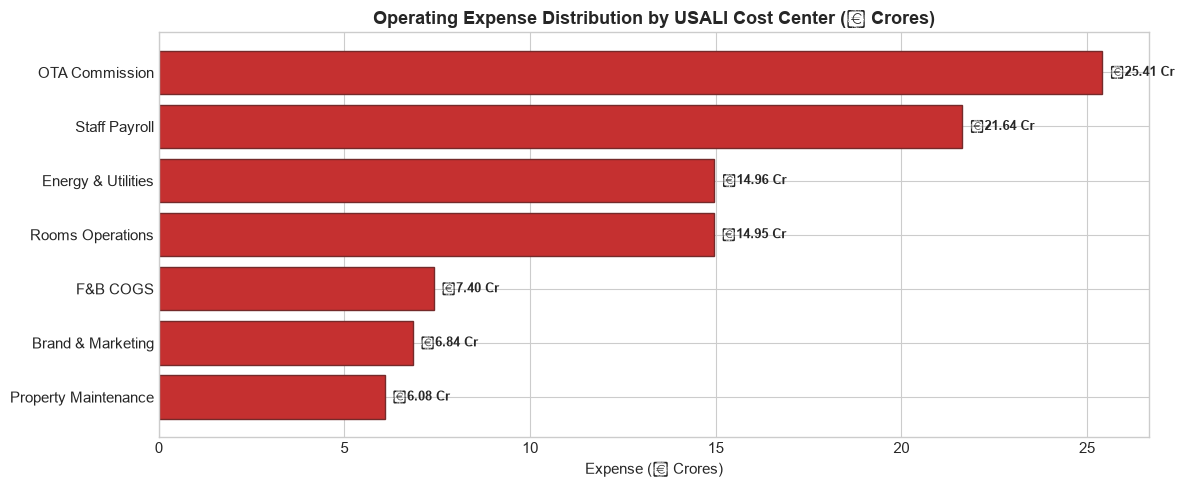

In [3]:
expense_cols = {
    'Rooms Operations': valid_cost['rooms_operating_cost_inr'].sum() / 1e7,
    'F&B COGS': valid_cost['fnb_cogs_operating_cost_inr'].sum() / 1e7,
    'OTA Commission': valid_cost['booking_distribution_commission_inr'].sum() / 1e7,
    'Energy & Utilities': valid_cost['energy_utility_cost_inr'].sum() / 1e7,
    'Staff Payroll': valid_cost['staff_payroll_allocated_inr'].sum() / 1e7,
    'Property Maintenance': valid_cost['property_maintenance_inr'].sum() / 1e7,
    'Brand & Marketing': valid_cost['marketing_brand_cost_inr'].sum() / 1e7,
}

df_exp = pd.DataFrame(list(expense_cols.items()), columns=['Expense Category', 'Amount_Cr']).sort_values(by='Amount_Cr', ascending=False)
display(df_exp)

plt.figure(figsize=(12, 5))
bars = plt.barh(df_exp['Expense Category'], df_exp['Amount_Cr'], color='#C53030', edgecolor='#742A2A')
plt.title('Operating Expense Distribution by USALI Cost Center (₹ Crores)', fontweight='bold', fontsize=13)
plt.xlabel('Expense (₹ Crores)')
plt.gca().invert_yaxis()

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.2, bar.get_y() + bar.get_height()/2, f'₹{w:,.2f} Cr', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()